Adding more terms
==

DIN supplement, cycling

Top-down control by zoop, virus

Depth-integrated?

In [1]:
import matplotlib.pyplot as plt
%matplotlib widget

In [2]:
import sys
s="/richmondvol1/rusty/stompy"
if s not in sys.path: sys.path.append(s) 
    
from importlib import reload
import time
import datetime
import os

import matplotlib.colorbar as cbar
import pandas as pd
import numpy as np
import xarray as xr

from scipy.integrate import solve_ivp
from matplotlib import colors, cm, ticker

from stompy import utils, memoize, xr_utils, xr_transect
import stompy.model.delft.dflow_model as dfm
import stompy.model.delft.waq_scenario as dwaq
from stompy.plot import plot_utils, plot_wkb, mkanim
import stompy.plot.cmap as scmap
from stompy.spatial import field, proj_utils
from stompy.grid import unstructured_grid

In [3]:
# These are online-coupled dfm-dwaq runs.
import bloom_common
reload(bloom_common)
from bloom_common import load_model, ratio, chl_from_RS

In [5]:
grid_poly = tracer_groups[0].grid.boundary_polygon()
turbo_low = scmap.cmap_transform(cm.turbo,lambda i: i**0.75)

INFO:utils:80874/86633
INFO:utils:2/16
INFO:utils:4/16
INFO:utils:6/16
INFO:utils:8/16
INFO:utils:10/16
INFO:utils:12/16
INFO:utils:14/16
INFO:join_features:0 open strings, 16 simple polygons
INFO:join_features:Building index
INFO:UnstructuredGrid:Warning, boundary_polygon() failed using edges!  Trying polygon union method


In [6]:
mooring_ll=pd.read_csv("../Kd_2022/L2/latlon.csv", sep="\t").set_index('station')
mooring_ll

,latitude,longitude
station,,
Dumbarton Bridge,37.50417,-122.119
Alviso Slough,37.44000,-121.998
San Mateo Bridge,37.58444,-122.249
Guadalupe Slough,37.43468,-122.026
Newark Slough,37.51338,-122.082
Mowry Slough,37.48536,-122.033
Pond A8 outlet,37.42348,-121.980
Coyote Creek,37.46384,-122.024
Shoal,37.63079,-122.243


In [7]:
# Mooring data:
mooring_csv="../Kd_2022/L2/SHL_all_data_L2.csv"
df_mooring = pd.read_csv(mooring_csv)
del df_mooring['Unnamed: 0']
df_mooring['time'] = pd.to_datetime(df_mooring['dt'])
df_mooring['time'] = df_mooring.time.values # should get back to UTC

# dt has the time zone in it, and .values should get a UTC timestamp, ready for comparison to model output
df_mooring = df_mooring.iloc[(df_mooring.time.values>np.datetime64("2022-08-01")) & (df_mooring.time.values<np.datetime64("2022-09-10")),:] 

In [8]:
df_mooring = df_mooring[ ['time','Chla_microgL','S_PSU','T_degC','Turb_FNU'] ]
df_mooring = df_mooring.set_index('time').resample('1H').mean().reset_index()


In [9]:
# For now just a single mooring, but could be multiple moorings
df_mooring['site']='SHL'

lonlat = np.r_[mooring_ll.loc['Shoal','longitude'], mooring_ll.loc['Shoal','latitude']]
xy = proj_utils.mapper('WGS84','EPSG:26910')(lonlat)
df_mooring['x']=xy[0]
df_mooring['y']=xy[1]
df_mooring.head()

,time,Chla_microgL,S_PSU,T_degC,Turb_FNU,site,x,y
0,2022-08-01 00:00:00,4.726667,32.536667,20.35200,17.306667,SHL,566794.980583,4.165121e+06
1,2022-08-01 01:00:00,4.572500,32.510000,20.32450,15.595000,SHL,566794.980583,4.165121e+06
2,2022-08-01 02:00:00,4.442500,32.492500,20.29250,12.702500,SHL,566794.980583,4.165121e+06
3,2022-08-01 03:00:00,4.385000,32.505000,20.27025,11.405000,SHL,566794.980583,4.165121e+06
4,2022-08-01 04:00:00,4.465000,32.552500,20.25500,12.560000,SHL,566794.980583,4.165121e+06


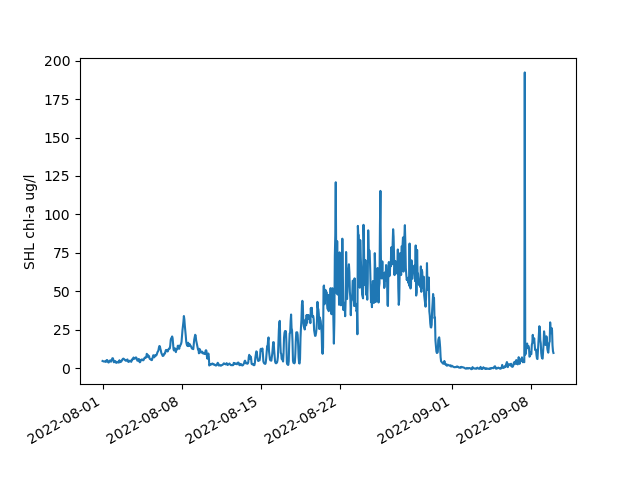

In [10]:
fig,ax = plt.subplots()

ax.plot(df_mooring.time, df_mooring.Chla_microgL)
ax.set_ylabel(f"{df_mooring.site.values[0]} chl-a ug/l")

fig.autofmt_xdate()

In [11]:
# Confirm mooring location
if 0:
    fig,ax=plt.subplots()
    grid=tracer_groups[0].grid
    grid.plot_edges(color='k',alpha=0.5,lw=0.5)
    ax.plot(df_mooring.iloc[0].x, df_mooring.iloc[0].y,'ro') ;

In [53]:
import tracer_group
reload(tracer_group)
from tracer_group import TracerGroup, tracer_groups

In [54]:
# Alameda release is basically zero until after the first pulse of bloom
#tg = [t for t in tracer_groups if t.tag=='v16' and t.swim==6.912 and t.initial=='alameda'][0]
tg = [t for t in tracer_groups if t.tag=='v17' and t.swim==6.912 and t.initial=='southbay'][0]

In [55]:
from stompy import memoize
class FitLagrangianToMooring:    
    # Any parameters that are available for tuning go here with defaults
    base_params=dict(
        thresh=1e-2,
        c0=3,
        kprod=1.0,
        N0=35, # initial DIN, uM
        Nsat=0.5, # half-sat DIN, uM
        Z0=0.1, # initial zoop. units?
        kmort=0.05,
        Isat=10.0,
        background=4.0, # baseline chl, added to result after the fact.
        alpha=0.15, # stoichiometry
        mu_Z=0.1, # growth rate for Zoop

    )

    # Which parameters to tune and their bounds
    params_to_tune=[('c0',0.5,5),
                ('kprod',0.3,3.0),
                ('kmort',0.0,0.5),
                ('Isat',1.0,80),
                ('background',0.0,15.0),
                ('Nsat',0.1,5.0)]

    # expects fields in dataframe:
    # x,y -  location of the sample
    # time 
    # Chla_microgL - 
    # 
    df_mooring=None
    group=None # tracer group
    layer=15 # model layer requires some preprocessing and it's discrete, not available for tuning
    light_lim='mean_lim' # approach to calculating light limitation
    # 'mean_lim', 'lim_mean'. May eventually have 'mean_lim_selfshade'
    # What to report when there's not enough tracer to do anything:
    P_nodata=np.nan
    N_nodata=np.nan 
    stride=1
    
    def __init__(self,params={},**kw):
        # Makes a copy for this instance. So you can have the "global" defaults defined above,
        # set some "instance" defaults, and still tune some parameters with different values within
        # and instance. 
        self.base_params = self.base_params | params # params will take precedence
        utils.set_keywords(self,kw)
        self.prepare_inputs()
        self.evaluate_parameter_set()

    @memoize.imemoize()
    def xy_to_cell(self,xy):
        return self.group.grid.select_cells_nearest(xy)
            
    def prepare_inputs(self):
        self.df_inputs = self.df_mooring.iloc[::self.stride].copy()

        xy = self.df_inputs[ ['x','y'] ].values
        cells = [self.xy_to_cell(p) for p in xy]
        self.df_inputs['cell']=cells
        # Some may be -1
        self.df_inputs['tidx']=utils.nearest(self.group.ds.time.values, self.df_inputs.time.values, max_dx = np.timedelta64(1,'h'))
        self.df_inputs = self.df_inputs.loc[ self.df_inputs.tidx>=0, :].copy()

        df_data = self.group.extract_timeseries(self.df_inputs.tidx.values, self.df_inputs.cell.values, layer=15)
        for col in df_data.columns:
            self.df_inputs[col] = df_data[col].values
        self.df_inputs['conc'] = self.df_inputs['conc'].clip(0.0)
        
        self.parameter_sets=[]

    def evaluate_parameter_set(self,**kw):
        """
        kw can include any fields from base_params.
        """
        t0=time.time()
        # params that are set across an evaluation of all the data points
        params=self.base_params | kw
        self.parameter_sets.append(params) # or just log kw
            
        # ODE integration
        # State vector is [N, P, Z, I, V]
    
        recs=[]
        
        for i,row in utils.progress(enumerate(self.df_inputs.itertuples())):
            constant_params=dict(params) # make a copy so code in this loop can use df_inputs to modify parameters. 
            IC=np.r_[params['N0'], params['c0']*row.conc, params['Z0'], params['I0'], params['V0']]
            age_d=row.age_d
            # self-shading would probably mean kLight is at least partially calculated inside the
            # integration
            constant_params['kLight']=bloom_common.calc_kLight(Isat=constant_params['Isat'],
                                                               kRadA=row.kRadA,IsatA=row.IsatA,
                                                               kRadB=row.kRadB,IsatB=row.IsatB,
                                                               conc=row.conc,age_d=row.age_d)
            if np.isnan(constant_params['kLight']):
                result = np.nan*IC
            elif age_d>0:
                bunch = solve_ivp(self.npziv_diff, y0=IC, t_span=[0,row.age_d], args=(constant_params,))
                result=bunch.y[:,-1]
            else:
                result = IC
            recs.append(dict(N=result[0],
                             P=result[1]+constant_params['background'],
                             Z=result[2],
                             I=result[3],
                             V=result[4],
                             time=row.time)
                        | constant_params)
        self.df_result=pd.DataFrame(recs)
    
        elapsed=time.time() - t0
        param_str=",".join( [f'{k}={params[k]:.3f}' for k in params] )
        #print(f"solveNPZIV({param_str}) in {elapsed:.3f}s")

    # Can override in subclass
    def npziv_diff(self, t, state, params):
        N,P,Z,I,V=np.clip(state,0,None)

        kDIN    =  N/(N+params['Nsat'])
        dgrossP =  params['kprod']*params['kLight']*kDIN*P
        dnetP   = -params['kmort']*P + dgrossP
        dN      = -params['alpha']*dgrossP
        dZ      =  params['mu_Z']*Z
        # default derivative ignores infected and virus state
        return np.r_[dN,dnetP,dZ,0,0]
        
    def fig_last_eval(self):
        fig,axs = plt.subplots(4,1,sharex=True,figsize=(7,6.5))

        ax=axs[0]
        ax.plot(self.df_mooring.time, self.df_mooring.Chla_microgL,label='Mooring')
        ax.plot(self.df_result.time, self.df_result.P, label='Lagrangian')
        ax.set_ylabel('Chl-a (ug/l)')
        ax.legend(loc='upper left')
        ax.axis(ymin=0)
        
        ax=axs[1]
        ax.plot(self.df_result.time, self.df_result.N)
        ax.set_ylabel('N ($\\mu$M)',color=ax.lines[0].get_color())
        ax.axis(ymin=-0.5)
        ax=ax.twinx()
        ax.plot(self.df_result.time, self.df_result.Z,color='tab:orange')
        ax.set_ylabel('Z (-)',color='tab:orange')
        
        ax=axs[2]
        ax.plot(self.df_inputs.time, self.df_inputs.conc)
        ax.set_ylabel('Tracer conc')
        ax.axis(ymin=-0.025)
        
        ax=axs[3]
        ax.plot(tuner.df_result.time, tuner.df_result.kLight)
        ax.set_ylabel('kLight (-)')
        ax.axis(ymin=0)
        
        fig.autofmt_xdate()
        fig.subplots_adjust(top=0.98,bottom=0.1,left=0.1,right=0.87,hspace=0.07)
        self.fig = fig

    def fig_last_eval_with_virus(self):
        fig,axs = plt.subplots(4,1,sharex=True,figsize=(7,6.5))

        ax=axs[0]
        ax.plot(self.df_mooring.time, self.df_mooring.Chla_microgL,label='Mooring')
        ax.plot(self.df_result.time, self.df_result.P, label='Lagrangian')
        ax.set_ylabel('Chl-a (ug/l)')
        ax.legend(loc='upper left')
        ax.axis(ymin=0)
        
        ax=axs[1]
        ax.plot(self.df_result.time, self.df_result.N)
        ax.set_ylabel('N ($\\mu$M)',color=ax.lines[0].get_color())
        ax.axis(ymin=-0.5)
        ax=ax.twinx()
        ax.plot(self.df_result.time, self.df_result.Z,color='tab:orange')
        ax.set_ylabel('Z (-)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=-0.01)
        
        ax=axs[2]
        ax.plot(tuner.df_result.time, tuner.df_result.I, color='tab:red')
        ax.set_ylabel('Infected (ug chl/l)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=0)
        ax=ax.twinx()
        ax.plot(tuner.df_result.time, tuner.df_result.V, color='tab:orange')
        ax.set_ylabel('Virus ($\\sim$VLP mL$^{-1}$)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=0)
        
        ax=axs[3]
        ax.plot(self.df_inputs.time, self.df_inputs.conc)
        ax.set_ylabel('Tracer conc')
        ax.axis(ymin=-0.025)
        
        fig.autofmt_xdate()
        fig.subplots_adjust(top=0.98,bottom=0.1,left=0.13,right=0.87,hspace=0.07)
        self.fig = fig

    def fig_last_eval_spatial(self):
        chl_cmap='turbo'
        chl_clim=[0,400]
        #chl_norm=colors.PowerNorm(0.4,*chl_clim)
        chl_norm=colors.LogNorm(chl_clim[1]*0.05, chl_clim[1], True)
    
        t=self.df_inputs['time'].values[0] # Assumes snapshot, all same time
    
        fig,axs=plt.subplots(1,2,figsize=(7.5,5))
        fig.subplots_adjust( wspace=0.04,top=0.97,right=0.97,left=0.03)
    
        for ax in axs: 
            ax.set_adjustable('box')
        
        ax=axs[0] # model results
        # Could cache fill_func on self
        P_result = self.df_result.P.values
        P_result = np.where( np.isfinite(P_result), P_result, 0.0) # fill in with 0.0
        coll=self.group.grid.plot_cells(values=fill_func(P_result), cmap=chl_cmap, norm=chl_norm, 
                                        lw=0.7,ec='face',ax=ax)
        if 1: # colorbar
            t_str = utils.strftime(t)
            cbar = plt.colorbar(coll,label="Chl-a ($\mu g \ l^{-1}$)\n"+t_str,ax=axs,orientation='horizontal',
                               pad=0.04,fraction=0.09,aspect=30)
            cax = cbar.ax
            cax.xaxis.set_minor_locator(ticker.LogLocator(subs='all'))
            cax.xaxis.set_minor_formatter(ticker.FormatStrFormatter('%d'))
            cax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))
        
        ax=axs[1] # RS data
        chl_rs = bloom_common.chl_from_RS(t,grid_poly)
        chl_rs.plot(ax=ax, cmap=chl_cmap, norm=chl_norm)
        
        for ax,label in zip(axs,['Lagrangian Model','Imagery']):
            ax.text(0.95,0.95,label,transform=ax.transAxes,ha='right',va='top')
        
        for ax in axs:
            ax.axis(zoom)
            plot_wkb.plot_wkb(grid_poly,lw=0.5,color='k',alpha=0.5,zorder=2, fc='none',ax=ax)
            ax.xaxis.set_visible(0)
            ax.yaxis.set_visible(0)
        return fig


In [56]:
class NPZIVModel(FitLagrangianToMooring):
    base_params=dict(
        N0=35, # initial DIN, uM
        # P0=c0*tracer conc
        Z0=0.1, # initial zoop. units?
        I0=0.0,
        V0=0.0,
        c0=3, # scale tracer output to get initial concentration
        kprod=1.0, # maximum instantaneous phyto growth rate [1/d]
        Nsat=0.5, # half-sat DIN, uM
        Isat=10.0, # half-sat for light, in some version(?) of W/m2
        kmortP=0.05, # phyto mortality rate [1/d]
        kmortZ=0.2, # zooplankton mortality rate [1/d]
        background=2.0, # baseline chl, added to result after the fact.
        alpha=0.15, # stoichiometry
        Z_efficiency=0.3, # growth efficiency for zoop,
        Z_max_ration=1.5, # maximum ration for zooplankton [1/d]
        mortP_to_N_efficiency = 0.5,
        N_supplement = 1.0, # uM/day
        thresh=1e-2,
        Ivlev=1.0, # Ivlev constant, 1.0  [ 1/(uM N) ]
        k_infect=0.0, # or 6.75e-8 [mL VLP^-1 day^-1] (adjust based on assumed units for P and V)default=5e-9
        lambda_lysis=1.5, # (float): Lysis rate of infected phytoplankton [day^-1]
        B=500, # viruses per 'host unit'; default=500
        k_virus=0.25, # Viral decay/inactivation rate [day^-1]
    )

    def npziv_diff(self, t, state, params):
        N,P,Z,I,V=np.clip(state,0,None)
        
        lim_DIN=N/(N+params['Nsat'])

        # No self-shading yet. 
        dgrossP = params['kprod']*params['kLight']*lim_DIN*P
        dmortP = params['kmortP']*P # positive value, but represents loss of P
        # Is this legit? Wikipedia says it is
        dgrazeP = Z*params['Z_max_ration']*(1-np.exp(-params['Ivlev']*P))

        # Virus
        # terms from basic_ode_phyto_graze_virus3.py
        # dPdt = mu_max /Kd_p * P - g * P - k * P * V
        # dIdt = k * P * V - lambda_lysis * I
        # dVdt = B * lambda_lysis * I - k * P * V - d_V * V
        # k (float): Viral infection rate constant (mL VLP^-1 day^-1).
        dinfectP = params['k_infect']*P*V
        
        dnetP = dgrossP - dmortP - dgrazeP - dinfectP

        dlyseI =  params['lambda_lysis'] * I
        
        # From DS equations, phytoplankton, when infected, are removed from P and added to I
        # at which point they lyse at a first order rate, and have no growth.
        dZ = params['Z_efficiency'] * dgrazeP - params['kmortZ']*Z
        # Wikipedia NPZ has 100% recycling efficiency for P and Z, including a (1-Z_efficiency) term
        # for "sloppy grazing"
        dN = (
            - params['alpha']*dgrossP # uptake
            + params['mortP_to_N_efficiency']*params['alpha']*dmortP # recycling
            + params['alpha'] * (1-params['Z_efficiency'])*dgrazeP
            + params['N_supplement'] # uM/day continual source
        )
        
        dI=dinfectP - dlyseI
        dV=params['B']*dlyseI - dinfectP - params['k_virus'] * V
        return np.r_[dN,dnetP,dZ,dI,dV]

INFO:utils:80195/86633
INFO:utils:1/16
INFO:utils:2/16
INFO:utils:3/16
INFO:utils:4/16
INFO:utils:5/16
INFO:utils:6/16
INFO:utils:7/16
INFO:utils:8/16
INFO:utils:9/16
INFO:utils:10/16
INFO:utils:11/16
INFO:utils:12/16
INFO:utils:13/16
INFO:utils:14/16
INFO:utils:15/16


TracerGroup Extract time series


INFO:utils:80/151


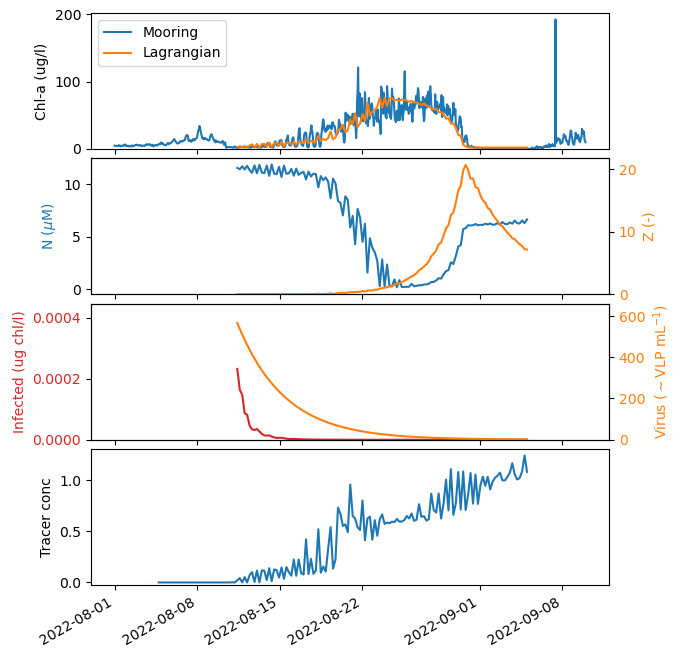

In [16]:
# An okay fit without virus.
tuner=NPZIVModel(group=tg,df_mooring=df_mooring, stride=5,
                 params=dict(c0=4,I0=5, N_supplement=0.1, N0=11, kprod=1.3,
                             Z_max_ration=2.1, Z0=0.0003))

tuner.fig_last_eval_with_virus();

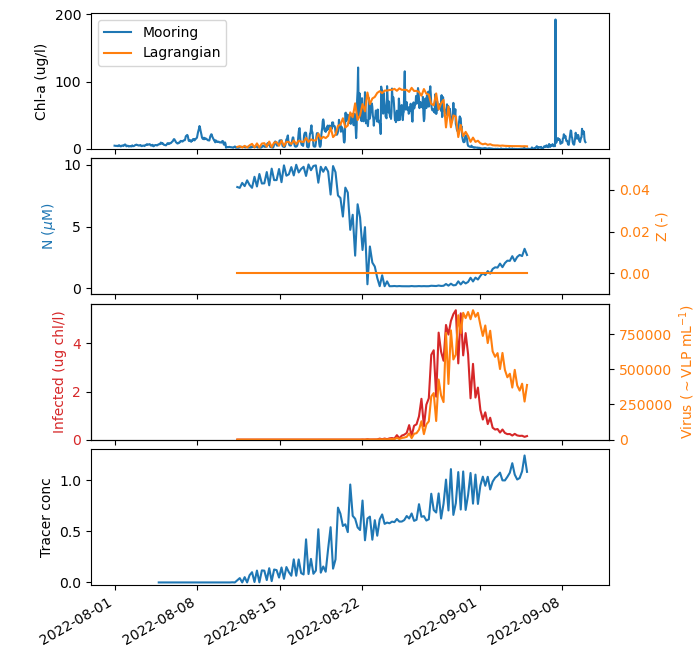

In [17]:
# Testing virus
tuner=NPZIVModel(group=tg,df_mooring=df_mooring, stride=5,
                 params=dict(N0=5, c0=4, Z0=0.0000, I0=1e-4, V0=200,
                             # virus params
                             k_infect=8.00e-7, B=20000, k_virus=0.25, lambda_lysis=4.0,
                             # other params
                             N_supplement=0.5, kprod=1.4, Z_max_ration=1.5, ))

tuner.fig_last_eval_with_virus()

Spatial Results
==

In [18]:
# construct dataframe of grid locations
zoom=(547000., 591059., 4139804., 4189355.)
grid_poly = tg.grid.boundary_polygon() # for clipping RS data

INFO:join_features:0 open strings, 16 simple polygons
INFO:join_features:Building index
INFO:UnstructuredGrid:Warning, boundary_polygon() failed using edges!  Trying polygon union method


In [48]:
t = tg.ds.time.values[150] # 400 middle/late 
cells = np.nonzero(tg.grid.cell_clip_mask(zoom))[0]
xy = tg.grid.cells_centroid(cells)

df_grid = pd.DataFrame()
df_grid['cell'] = cells
df_grid['x'] = xy[:,0]
df_grid['y'] = xy[:,1]
df_grid['time'] = t

df_grid = df_grid.iloc[::15] # solve for only a subset, then interpolate

In [20]:
# as long as the grid and stride don't change this can be precomputed.
# note: count here needs to be roughly 3x the stride, in order for all
# of the cells within South Bay to get filled in
fill_func = tg.grid.fill_by_smoothing_func(df_grid.cell.values, count=45) # 20s

INFO:utils:80639/86633


In [57]:
# virus, spatial
# 360 samples per 5 s.
# 30k samples in df_grid
# stride of 5 that's 6k samples, takes 1.5 minutes or so
tuner=NPZIVModel(group=tg,df_mooring=df_grid, stride=1,
                 params=dict(N0=5, c0=4, Z0=0.0000, I0=1e-4, V0=200,
                             # virus params
                             k_infect=8.00e-7, B=20000, k_virus=0.25, lambda_lysis=4.0,
                             # other params
                             N_supplement=0.5, kprod=1.4, Z_max_ration=1.5, ))

TracerGroup Extract multiple cells, single time step


INFO:utils:1048


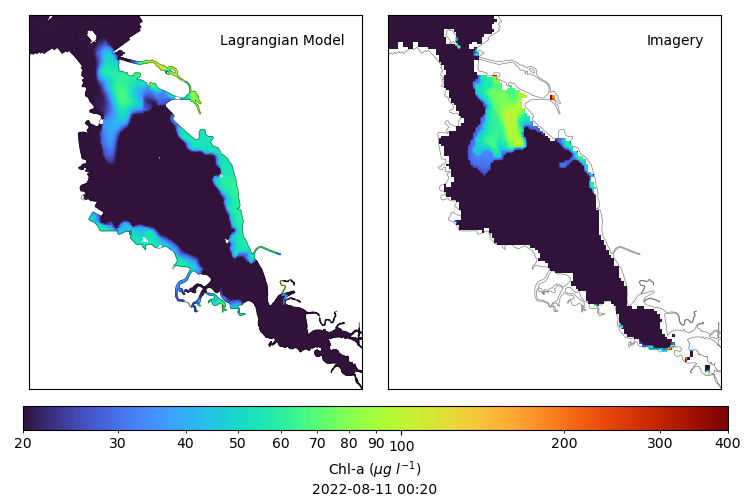

In [58]:
fig=tuner.fig_last_eval_spatial()

In [ ]:
# Render animation
frame_dir = "frames-bloom_lagrangian_zoop_etal-v000"
if not os.path.exists(frame_dir):
    os.makedirs(frame_dir)

times=tg.ds.time.values

for tidx,t in enumerate(times):
    tuner=NPZIVModel(group=tg,df_mooring=df_grid, stride=1,
                 params=dict(N0=5, c0=4, Z0=0.0000, I0=1e-4, V0=200,
                             # virus params
                             k_infect=8.00e-7, B=20000, k_virus=0.25, lambda_lysis=4.0,
                             # other params
                             N_supplement=0.5, kprod=1.4, Z_max_ration=1.5, ))
    tuner.fig_last_eval_spatial()


NPZIV Results
==



In [87]:
# Stoichiometry for DIN vs chl
alpha1 = 6.625 # = 1mol N * 106molC/16 mol N = mol C ; 1mol CO2 fixed * 1mol O2 / 1mol CO2 , 1:1
c_chl = 1/0.03
alpha2 = alpha1*12/c_chl # = 2.385 ug chl / umol N ....106 umol C / 16 umol N * 12 ug C / umol C * 0.03 ug chl / 1 ug
alpha2
1.0/alpha2 # uM DIN / ug/l Chl-a

0.41928721174004197

Diagnostics for tidal phase
==

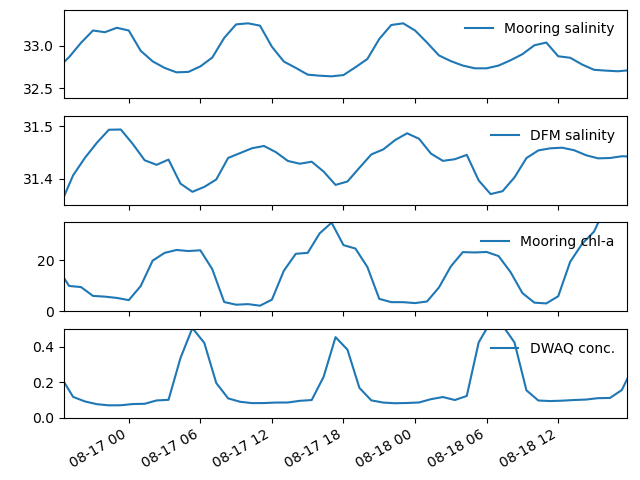

In [215]:
# Is there enough salt to diagnose phase? yes - and phase appears correct.
fig,axs=plt.subplots(4,1,sharex=True)
axs[0].plot( df_mooring.time, df_mooring.S_PSU, label='Mooring salinity')

axs[1].plot( tg.ds.time.values, tg.ds['sa1'].isel(laydim=15,nFlowElem=16145),
           label='DFM salinity')

axs[2].plot( df_mooring.time, df_mooring.Chla_microgL,label='Mooring chl-a')

axs[3].plot( tg.ds.time.values, tg.ds[f'conc{tg.suffix}'].isel(laydim=15,nFlowElem=16145),
           label='DWAQ conc.')

for ax in axs:
    ax.legend(loc='upper right', frameon=0)
    
fig.autofmt_xdate()
axs[0].axis((19220.7738, 19222.7409, 32.38, 33.43))
axs[1].axis(ymin=31.35,ymax=31.52)
axs[2].axis(ymin=0,ymax=35)
axs[3].axis(ymin=0,ymax=0.5)
fig.subplots_adjust(right=0.98,bottom=0.13,top=0.98,left=0.10)


OLD
==

In [ ]:
    def prepare_inputs(self):
        self.snaps=[]
        for tidx in self.train_tidxs:
            t=self.group.ds.time.values[tidx]
            snap=dict(tidx=tidx,t=t,
                      rs_chl=chl_from_RS(t,grid_poly))
            rs_chl=snap['rs_chl'].crop(self.train_zoom)
            if self.downsample!=1:
                rs_chl=rs_chl.downsample(self.downsample,method='mean')
            X,Y = rs_chl.XY()
            valid=np.isfinite(rs_chl.F)
            snap['rs_xy_chl'] = np.c_[X[valid],Y[valid],rs_chl.F[valid]]

            # grid cell indexes in order of the cropped, valid rs_chl pixels
            snap['cells']=np.array([self.group.grid.select_cells_nearest(xy) for xy in snap['rs_xy_chl'][:,:2]])
            # bitmask of cells to be computed.
            cell_sel=np.zeros(self.group.grid.Ncells(),bool)
            cell_sel[snap['cells']] = True
            snap['cell_sel']=cell_sel
            self.snaps.append(snap)
        self.base_params=dict(thresh=self.thresh,
                              c0=self.c0,
                              kprod=self.kprod,
                              N0=self.N0, # initial DIN, uM
                              Nsat=self.Nsat, # half-sat DIN, uM
                              kmort=self.kmort,
                              Isat=self.Isat,
                              background=self.background)
        self.parameter_sets=[]
            


    def tune(self,minimize_kw={}):
        self.vec0 = [getattr(self,p[0]) for p in self.params_to_tune]
        self.bounds = [p[1:3] for p in self.params_to_tune]
        
        def cost(vec):
            kw={p[0]:x for p,x in zip(self.params_to_tune,vec)}
            return self.evaluate_parameter_set(**kw)
                
        self.min_result = minimize(cost, self.vec0, bounds=self.bounds, **minimize_kw)

    def fig_last_eval(self,chl_clim=[0,60],cmap='turbo'):
        fig,axs=plt.subplots(2,len(self.snaps), figsize=(11,6))
        fig.subplots_adjust(left=0.02,right=0.98,top=0.98,bottom=0.05,hspace=0.03,wspace=0.03)
        for ax in axs.ravel():
            ax.set_adjustable('datalim')
            ax.xaxis.set_visible(0)
            ax.yaxis.set_visible(0)
            ax.axis('equal')
            
        for i,snap in enumerate(self.snaps):
            axs[0,i].scatter(snap['rs_xy_chl'][:,0],snap['rs_xy_chl'][:,1],8,snap['rs_xy_chl'][:,2],cmap=cmap,clim=chl_clim)
            axs[1,i].scatter(snap['rs_xy_chl'][:,0],snap['rs_xy_chl'][:,1],8,snap['last_model_chl'],cmap=cmap,clim=chl_clim)
            axs[0,i].text(0.98,0.98,"RS " + utils.strftime(snap['t'],'%Y-%m-%d %H:%M'),transform=axs[0,i].transAxes,
                          va='top',ha='right')
            axs[1,i].text(0.98,0.98,"Model",transform=axs[1,i].transAxes,va='top',ha='right')
    
        return fig

    def fig_last_eval_dense(self,chl_clim=[0,60],cmap='inferno'):
        fig,axs=plt.subplots(2,len(self.snaps), figsize=(11,4.5))
        fig.subplots_adjust(left=0.05,right=0.98,top=0.87,bottom=0.27,hspace=0.03,wspace=0.03)
        for ax in axs.ravel():
            ax.set_adjustable('datalim')
            ax.axis('equal')
            plot_wkb.plot_wkb(grid_poly,ec='k',fc='none',lw=0.7,zorder=2,ax=ax)
            
        for i,snap in enumerate(self.snaps):
            axs[0,i].scatter(snap['rs_xy_chl'][:,0],snap['rs_xy_chl'][:,1],8,snap['rs_xy_chl'][:,2],cmap=cmap,clim=chl_clim)
            axs[1,i].scatter(snap['rs_xy_chl'][:,0],snap['rs_xy_chl'][:,1],8,snap['last_model_chl'],cmap=cmap,clim=chl_clim)
            axs[0,i].text(0.5,1.02,utils.strftime(snap['t'],'%m/%d'),transform=axs[0,i].transAxes,
                          va='bottom',ha='center',fontsize=15)
    
        for ax in axs.ravel():
            ax.axis(self.train_zoom)
            ax.set_xticks([])
            ax.set_yticks([])
        axs[0,0].set_ylabel('RS',fontsize=16)
        axs[1,0].set_ylabel('Model',fontsize=16)
        cax=fig.add_axes([0.35,0.15,0.3,0.04])
        cbar = plt.colorbar(axs[0,0].collections[0],cax=cax,orientation='horizontal')
        cbar.set_label(r'chl-a $\mu$g l$^{-1}$',fontsize=15)
        plt.setp(cax.get_xticklabels(),fontsize=15)
        return fig

In [12]:
# New Kd:
tg = [t for t in tracer_groups if t.tag=='v16' and t.swim==6.912 and t.initial=='alameda'][0]
tuner_0=FitLagrangianToRS(group=tg,train_tidxs=[73,97,121,145,169,193,217,241,265,289], downsample=3)
tuner_0.tune(minimize_kw=dict(method='Powell'))

solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.74 in 0.045s
solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.74 in 2.445s
solveNP(thresh=0.010,c0=2.219,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.69 in 0.046s
solveNP(thresh=0.010,c0=3.281,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.47 in 0.045s
solveNP(thresh=0.010,c0=3.938,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.05 in 0.045s
solveNP(thresh=0.010,c0=4.722,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.90 in 0.045s
solveNP(thresh=0.010,c0=4.631,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.90 in 0.046s
solveNP(thresh=0.010,c0=4.625,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.90 in 0.045s


In [16]:
# optimize only over earlier runs. - little difference
tg = [t for t in tracer_groups if t.tag=='v16' and t.swim==6.912 and t.initial=='alameda'][0]
tuner_0=FitLagrangianToRS(group=tg,train_tidxs=[73,97,121,145,169,193], downsample=3)
tuner_0.tune(minimize_kw=dict(method='Powell'))

solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.82 in 1.507s
solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.82 in 0.407s
solveNP(thresh=0.010,c0=2.219,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=17.69 in 0.026s
solveNP(thresh=0.010,c0=3.281,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.65 in 0.026s
solveNP(thresh=0.010,c0=3.938,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.55 in 0.026s
solveNP(thresh=0.010,c0=3.761,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.54 in 0.026s
solveNP(thresh=0.010,c0=3.755,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.54 in 0.026s
solveNP(thresh=0.010,c0=3.756,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.54 in 0.025s


In [13]:
# Tune 6.912 against more data

tg = [t for t in tracer_groups if t.tag=='v13' and t.swim==6.912 and t.initial=='alameda'][0]
tuner_6=FitLagrangianToRS(group=tg,train_tidxs=[73,97,121,145,169,193,217,241,265,289], downsample=3)

# solveNP(thresh=0.010,c0=1.156,kprod=1.915,N0=35.000,Nsat=4.999,kmort=0.067,Isat=7.001,background=8.776) err=10.21 in 0.801s
tuner_6.tune(minimize_kw=dict(method='Powell'))

INFO:utils:82431/86633
INFO:utils:1/16
INFO:utils:2/16
INFO:utils:3/16
INFO:utils:4/16
INFO:utils:5/16
INFO:utils:6/16
INFO:utils:7/16
INFO:utils:8/16
INFO:utils:9/16
INFO:utils:10/16
INFO:utils:11/16
INFO:utils:12/16
INFO:utils:13/16
INFO:utils:14/16
INFO:utils:15/16


solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.53 in 5.444s
solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.53 in 0.698s
solveNP(thresh=0.010,c0=2.219,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.54 in 0.044s
solveNP(thresh=0.010,c0=3.281,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.25 in 0.044s
solveNP(thresh=0.010,c0=3.938,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.80 in 0.045s
solveNP(thresh=0.010,c0=4.777,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.62 in 0.044s
solveNP(thresh=0.010,c0=4.673,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.62 in 0.045s
solveNP(thresh=0.010,c0=4.666,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.62 in 0.044s


In [15]:
tg = [t for t in tracer_groups if t.tag=='v12' and t.swim==6.912 and t.initial=='alameda'][0]
tuner_6=FitLagrangianToRS(group=tg,train_tidxs=[73,97,121,145,169,193,217,241,265,289], downsample=3)
tuner_6.tune(minimize_kw=dict(method='Powell'))

INFO:utils:82540/86633


KeyError: 'kRadA3 is not an existing variable'

In [14]:
# New Kd, no swimming
tg = [t for t in tracer_groups if t.tag=='v16' and t.swim==0.0 and t.initial=='alameda'][0]
tuner_0=FitLagrangianToRS(group=tg,train_tidxs=[73,97,121,145,169,193,217,241,265,289], downsample=3)
tuner_0.tune(minimize_kw=dict(method='Powell'))

solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.72 in 5.376s
solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.72 in 0.670s
solveNP(thresh=0.010,c0=2.219,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=21.63 in 0.045s
solveNP(thresh=0.010,c0=3.281,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.43 in 0.044s
solveNP(thresh=0.010,c0=3.938,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.84 in 0.044s
solveNP(thresh=0.010,c0=4.343,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.54 in 0.044s
solveNP(thresh=0.010,c0=4.594,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.38 in 0.044s
solveNP(thresh=0.010,c0=4.749,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.29 in 0.044s


In [93]:
def fig_last_eval_dense(self,chl_clim=[0,60],cmap='inferno'):
    fig,axs=plt.subplots(2,len(self.snaps), figsize=(11,4.5))
    fig.subplots_adjust(left=0.05,right=0.98,top=0.87,bottom=0.27,hspace=0.03,wspace=0.03)
    for ax in axs.ravel():
        ax.set_adjustable('datalim')
        ax.axis('equal')
        plot_wkb.plot_wkb(grid_poly,ec='k',fc='none',lw=0.7,zorder=2,ax=ax)
        
    for i,snap in enumerate(self.snaps):
        axs[0,i].scatter(snap['rs_xy_chl'][:,0],snap['rs_xy_chl'][:,1],8,snap['rs_xy_chl'][:,2],cmap=cmap,clim=chl_clim)
        axs[1,i].scatter(snap['rs_xy_chl'][:,0],snap['rs_xy_chl'][:,1],8,snap['last_model_chl'],cmap=cmap,clim=chl_clim)
        axs[0,i].text(0.5,1.02,utils.strftime(snap['t'],'%m/%d'),transform=axs[0,i].transAxes,
                      va='bottom',ha='center',fontsize=15)

    for ax in axs.ravel():
        ax.axis(self.train_zoom)
        ax.set_xticks([])
        ax.set_yticks([])
    axs[0,0].set_ylabel('RS',fontsize=16)
    axs[1,0].set_ylabel('Model',fontsize=16)
    cax=fig.add_axes([0.35,0.15,0.3,0.04])
    cbar = plt.colorbar(axs[0,0].collections[0],cax=cax,orientation='horizontal')
    cbar.set_label(r'chl-a $\mu$g l$^{-1}$',fontsize=15)
    plt.setp(cax.get_xticklabels(),fontsize=15)
    return fig

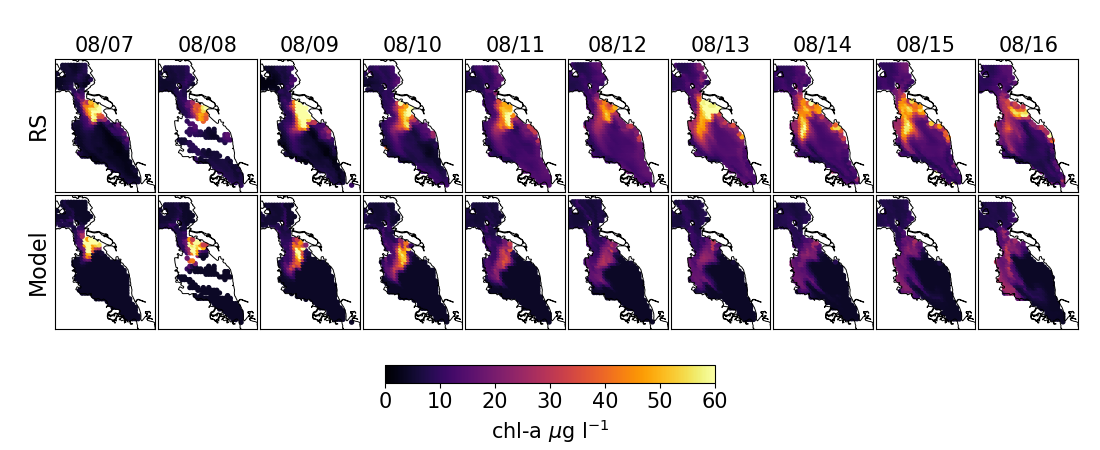

In [94]:
utils.add_to(tuner)(fig_last_eval_dense)

tuner.fig_last_eval_dense(cmap='inferno') ;

In [95]:
tg = [t for t in tracer_groups if t.tag=='v13' and t.swim==6.912j and t.initial=='alameda'][0]
tuner_6j=FitLagrangianToRS(group=tg,train_tidxs=[73,97,121,145,169,193,217,241,265,289], downsample=3)
tuner_6j.tune(minimize_kw=dict(method='Powell'))
#solveNP(thresh=0.010,c0=1.179,kprod=1.874,N0=35.000,Nsat=5.000,kmort=0.069,Isat=5.560,background=8.763) err=10.18 in 0.802s

solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.45 in 5.138s
solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.45 in 0.705s
solveNP(thresh=0.010,c0=2.219,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.47 in 0.045s
solveNP(thresh=0.010,c0=3.281,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.17 in 0.045s
solveNP(thresh=0.010,c0=3.938,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.71 in 0.045s
solveNP(thresh=0.010,c0=4.751,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.54 in 0.045s
solveNP(thresh=0.010,c0=4.648,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.54 in 0.045s
solveNP(thresh=0.010,c0=4.642,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.54 in 0.045s


In [84]:
# Might have had a 1h shift in RS data.
# Flyovers are 1820 UTC, which is 1120 PDT, but I've been plotting 1220 PDT 
tg = [t for t in tracer_groups if t.tag=='v13' and t.swim==6.912j and t.initial=='alameda'][0]
tidx_off=-1
tuner_6jb=FitLagrangianToRS(group=tg,
                           train_tidxs=[73+tidx_off,97+tidx_off,121+tidx_off,145+tidx_off,169+tidx_off,
                                        193+tidx_off,217+tidx_off,241+tidx_off,265+tidx_off,289+tidx_off], 
                           downsample=3)
tuner_6jb.tune(minimize_kw=dict(method='Powell'))

# With the _sfei chl imagery:
# solveNP(thresh=0.010,c0=1.364,kprod=1.784,N0=35.000,Nsat=5.000,kmort=0.067,Isat=6.102,background=8.926) err=10.08 in 0.779s
# With the _raphe chl imagery:
# solveNP(thresh=0.010,c0=1.962,kprod=1.791,N0=35.000,Nsat=5.000,kmort=0.075,Isat=4.204,background=11.407) err=15.54 in 0.769s


INFO:utils:78056/86633


solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.29 in 5.578s
solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.29 in 1.105s
solveNP(thresh=0.010,c0=2.219,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.37 in 0.045s
solveNP(thresh=0.010,c0=3.281,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.99 in 0.044s
solveNP(thresh=0.010,c0=3.938,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.48 in 0.044s
solveNP(thresh=0.010,c0=4.343,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.31 in 0.044s
solveNP(thresh=0.010,c0=4.789,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.25 in 0.045s
solveNP(thresh=0.010,c0=4.766,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.25 in 0.044s


/tmp/ipykernel_3147863/3287273092.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,axs=plt.subplots(2,len(self.snaps), figsize=(11,4.5))


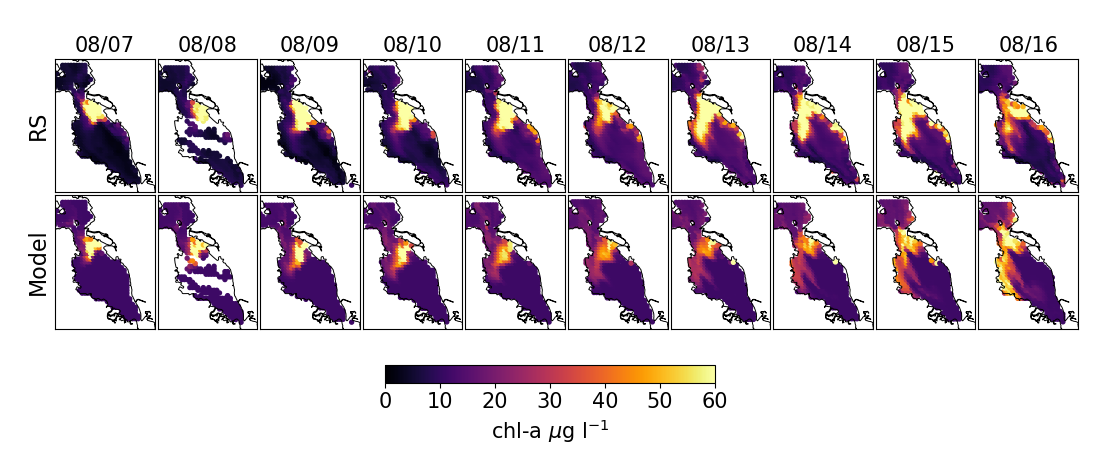

In [99]:
utils.add_to(tuner_6jb)(fig_last_eval_dense)

tuner_6jb.fig_last_eval_dense(cmap='inferno') ;

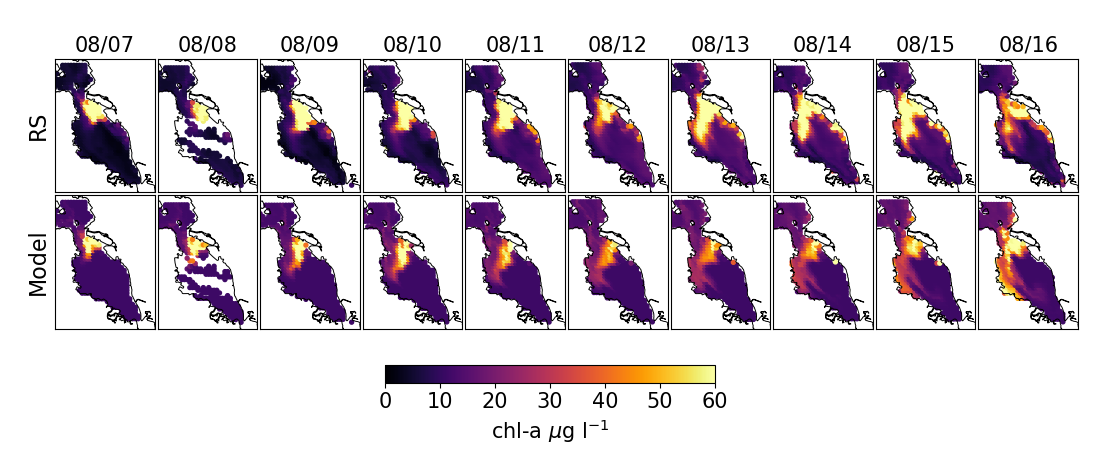

In [100]:
utils.add_to(tuner_6j)(fig_last_eval_dense)
tuner_6j.fig_last_eval_dense(cmap='inferno') ;

In [101]:
tg = [t for t in tracer_groups if t.tag=='v13' and t.swim==0.0 and t.initial=='alameda'][0]
tidx_off=-1
tuner_0=FitLagrangianToRS(group=tg,
                          # train_tidxs=[73,97,121,145,169,193,217,241,265,289],
                          train_tidxs=[73+tidx_off,97+tidx_off,121+tidx_off,145+tidx_off,169+tidx_off,
                                        193+tidx_off,217+tidx_off,241+tidx_off,265+tidx_off,289+tidx_off],
                          downsample=3)
tuner_0.tune(minimize_kw=dict(method='Powell'))
# with no offset:
# solveNP(thresh=0.010,c0=1.610,kprod=1.946,N0=35.000,Nsat=5.000,kmort=0.098,Isat=5.061,background=10.887) err=10.27 in 0.789s
# -1 offset
# solveNP(thresh=0.010,c0=2.037,kprod=1.755,N0=35.000,Nsat=5.000,kmort=0.071,Isat=7.097,background=9.615) err=10.22 in 0.779s

solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.47 in 0.682s
solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.47 in 0.683s
solveNP(thresh=0.010,c0=2.219,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=21.44 in 0.044s
solveNP(thresh=0.010,c0=3.281,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=20.15 in 0.044s
solveNP(thresh=0.010,c0=3.938,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.51 in 0.044s
solveNP(thresh=0.010,c0=4.343,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.18 in 0.044s
solveNP(thresh=0.010,c0=4.594,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.00 in 0.045s
solveNP(thresh=0.010,c0=4.749,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.90 in 0.044s


In [102]:
print("Change in IC scaling",2.037/1.364) 
print("Change in kprod",1.755/1.784) # 9% higher growth rate

Change in IC scaling 1.4934017595307916
Change in kprod 0.983744394618834


In [103]:
# Diffusion run!
# solveNP(thresh=0.010,c0=1.948,kprod=1.416,N0=35.000,Nsat=2.078,kmort=0.038,Isat=10.604,background=8.207) err=9.27 in 0.790s
# numerically better, esp. more physical parameter values, but visually not that great. 
tg = [t for t in tracer_groups if t.tag=='v15' and t.swim==6.912j and t.initial=='alameda'][0]
tg.ds.reload()

tidx_off=-1
tuner_diff=FitLagrangianToRS(group=tg,
                          train_tidxs=[73+tidx_off,97+tidx_off,121+tidx_off,145+tidx_off,169+tidx_off,
                                        193+tidx_off,217+tidx_off,241+tidx_off,265+tidx_off,289+tidx_off],
                          downsample=3)
tuner_diff.tune(minimize_kw=dict(method='Powell'))

INFO:utils:78130/86633


solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.33 in 4.999s
solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=18.33 in 0.705s
solveNP(thresh=0.010,c0=2.219,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=19.80 in 0.045s
solveNP(thresh=0.010,c0=3.281,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=17.85 in 0.045s
solveNP(thresh=0.010,c0=3.938,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.89 in 0.045s
solveNP(thresh=0.010,c0=4.343,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.40 in 0.045s
solveNP(thresh=0.010,c0=4.594,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.14 in 0.045s
solveNP(thresh=0.010,c0=4.749,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=16.00 in 0.045s


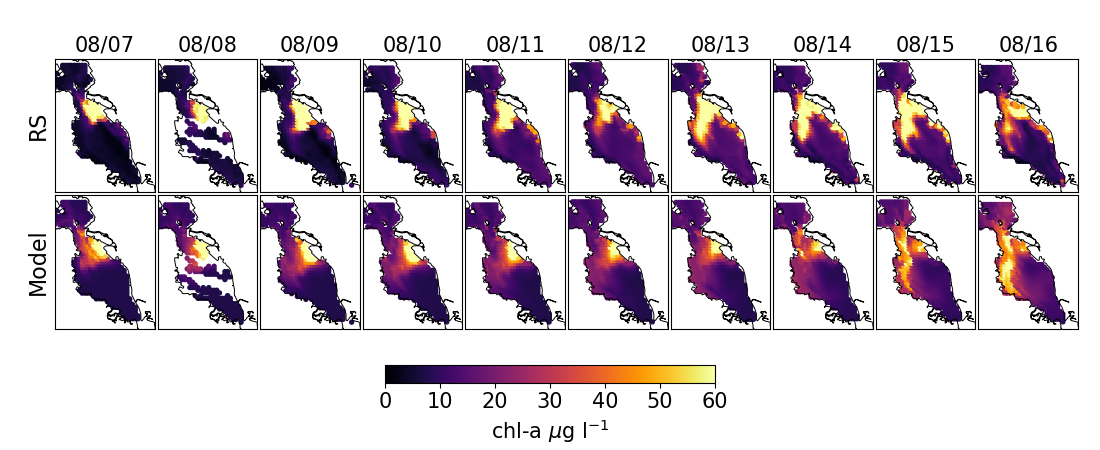

In [104]:
utils.add_to(tuner_diff)(fig_last_eval_dense)
tuner_diff.fig_last_eval_dense(cmap='inferno') ;


Other Groups
--

In [106]:
tg = [t for t in tracer_groups if t.tag=='v13' and t.swim==6.912j and t.initial=='southbay'][0]
tuner=FitLagrangianToRS(group=tg)
minimize(cost, vec0, (tuner,), method='Powell', bounds=bounds)

solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=98.82 in 0.091s


NameError: name 'cost' is not defined

In [107]:
tg = [t for t in tracer_groups if t.tag=='v13' and t.swim==0.0 and t.initial=='southbay'][0]
tuner=FitLagrangianToRS(group=tg)
minimize(cost, vec0, (tuner,), method='Powell', bounds=bounds)

solveNP(thresh=0.010,c0=3.000,kprod=1.000,N0=35.000,Nsat=0.500,kmort=0.050,Isat=10.000,background=4.000) err=100.34 in 1.326s


NameError: name 'cost' is not defined

In [ ]:
tg = [t for t in tracer_groups if t.tag=='v13' and t.swim==6.912 and t.initial=='southbay'][0]
tuner=FitLagrangianToRS(group=tg)
minimize(cost, vec0, (tuner,), method='Powell', bounds=bounds)